In [199]:
import sys
sys.path.append("..")

In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [201]:
df_ch_przeplyw = pd.read_parquet('../data/processed/Chorzów/przeplyw.parquet')
df_ch_scieki = pd.read_parquet('../data/processed/Chorzów/scieki.parquet')
df_ch_awarie = pd.read_parquet('../data/processed/Chorzów/awarie.parquet')
df_ch_energia = pd.read_parquet('../data/processed/Chorzów/energia.parquet')
df_ch_opady = pd.read_parquet('../data/processed/Chorzów/suma_opadow.parquet')

### LightGBM
Model ma się uczyć zależności między ilością przepompowanych ścieków, a opadami atmosferycznymi.
Nie tylko przewidywanie pompowania na podstawie poprzednich godzin, ale uwzględnienie jak to reagowało na deszcz

CEL: Wykrywanie sytuacji, w których ilość przepompowanych ścieków jest większa niż powinna być przy danych warunkach opadowych - czy powinniśmy się spodziewać aż tak dużej ilości ścieków?

LightGBM - ma wyznaczać oczekiwane pompowanie (na podtsaiwe historycznej zależności między opadami, porą dnia, ilością ścieków) i
ma wykrywać nadwyżki względem pogody

In [202]:
df = df_ch_scieki.copy()

df["Sposób_pomiaru"] = df["Sposób_pomiaru"].astype(str).str.strip()
df = df[df["Sposób_pomiaru"] == "Wartość z pomiaru"].copy()


if "Data_czas" in df.columns:
    df["Data_czas"] = pd.to_datetime(df["Data_czas"])
    df = df.set_index("Data_czas")

df = df.rename(columns={"Ilosc_przepompowanych_sciekow": "ilosc"})

# konwersja na liczbowe
df["ilosc"] = pd.to_numeric(
    df["ilosc"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

# usuwanie zer i śmieci
df = df[df["ilosc"].notna()]
print(df[["ilosc"]].head(10))

                         ilosc
Data_czas                     
2024-10-13 00:00:00  4891880.0
2024-10-13 00:00:54  4891880.0
2024-10-13 00:01:06  4891880.0
2024-10-13 00:01:18  4891890.0
2024-10-13 00:01:26  4891890.0
2024-10-13 00:01:52  4891890.0
2024-10-13 00:14:04  4891890.0
2024-10-13 00:14:20  4891890.0
2024-10-13 00:14:34  4891890.0
2024-10-13 00:14:44  4891890.0


In [203]:
# Mamy zduplikowane daty (najprawdopodobniej wynikają ze zmiany czasu na zimowy/letni), więc zachowamy te największe odczyty dla każdej daty
df = df.groupby(level=0).agg({"ilosc": "max"})
df = df.sort_index()

df.head()


,ilosc
Data_czas,
2024-10-13 00:00:00,4891880.0
2024-10-13 00:00:54,4891880.0
2024-10-13 00:01:06,4891880.0
2024-10-13 00:01:18,4891890.0
2024-10-13 00:01:26,4891890.0


In [204]:
df_ch_opady["Data_czas"] = pd.to_datetime(df_ch_opady["Data_czas"])
df_ch_opady = df_ch_opady.set_index("Data_czas").sort_index()

print(df_ch_opady.head())

                     suma_opadu_mm
Data_czas                         
2024-01-01 00:00:00            0.0
2024-01-01 01:00:00            0.0
2024-01-01 02:00:00            0.0
2024-01-01 03:00:00            0.0
2024-01-01 04:00:00            0.0


In [205]:
hourly = df["ilosc"].resample("1h").last()
df_1h = pd.DataFrame({
    "przepompowano": hourly.diff()
})

df_lgbm = df_1h.join(df_ch_opady[["suma_opadu_mm"]], how="left")

print(df_lgbm.head(10))

                     przepompowano  suma_opadu_mm
Data_czas                                        
2024-10-13 00:00:00            NaN            0.0
2024-10-13 01:00:00           10.0            0.0
2024-10-13 02:00:00           20.0            0.0
2024-10-13 03:00:00           10.0            0.0
2024-10-13 04:00:00           20.0            0.0
2024-10-13 05:00:00           10.0            0.0
2024-10-13 06:00:00           20.0            0.0
2024-10-13 07:00:00           10.0            0.0
2024-10-13 08:00:00           30.0            0.0
2024-10-13 09:00:00           20.0            0.0


In [206]:
df_lgbm = df_lgbm[~df_lgbm.index.duplicated(keep=False)].copy()
print("Duplikaty:", df_lgbm.index.duplicated().sum())

Duplikaty: 0


In [207]:
#Dajemy modelowi kontekst kalendarzowy, ponieważ może zależeć od pory dnia i dnia tygodnia
df_lgbm["hour"] = df_lgbm.index.hour
df_lgbm["dayofweek"] = df_lgbm.index.day_of_week
df_lgbm["month"] = df_lgbm.index.month
df_lgbm["weekend"] = (df_lgbm.index.day_of_week >= 5).astype(int)

print(df_lgbm.head(10))

                     przepompowano  suma_opadu_mm  hour  dayofweek  month  \
Data_czas                                                                   
2024-10-13 00:00:00            NaN            0.0     0          6     10   
2024-10-13 01:00:00           10.0            0.0     1          6     10   
2024-10-13 02:00:00           20.0            0.0     2          6     10   
2024-10-13 03:00:00           10.0            0.0     3          6     10   
2024-10-13 04:00:00           20.0            0.0     4          6     10   
2024-10-13 05:00:00           10.0            0.0     5          6     10   
2024-10-13 06:00:00           20.0            0.0     6          6     10   
2024-10-13 07:00:00           10.0            0.0     7          6     10   
2024-10-13 08:00:00           30.0            0.0     8          6     10   
2024-10-13 09:00:00           20.0            0.0     9          6     10   

                     weekend  
Data_czas                     
2024-10-13 00

In [208]:
df_lgbm["lag_1h"] = df_lgbm["przepompowano"].shift(1)
df_lgbm["lag_3h"] = df_lgbm["przepompowano"].shift(3)
df_lgbm["lag_6h"] = df_lgbm["przepompowano"].shift(6)
df_lgbm["lag_12h"] = df_lgbm["przepompowano"].shift(12)
df_lgbm["lag_24h"] = df_lgbm["przepompowano"].shift(24)
df_lgbm["lag_48h"] = df_lgbm["przepompowano"].shift(48)
df_lgbm["lag_168h"] = df_lgbm["przepompowano"].shift(168)

print(df_lgbm.head(30))

                     przepompowano  suma_opadu_mm  hour  dayofweek  month  \
Data_czas                                                                   
2024-10-13 00:00:00            NaN            0.0     0          6     10   
2024-10-13 01:00:00           10.0            0.0     1          6     10   
2024-10-13 02:00:00           20.0            0.0     2          6     10   
2024-10-13 03:00:00           10.0            0.0     3          6     10   
2024-10-13 04:00:00           20.0            0.0     4          6     10   
2024-10-13 05:00:00           10.0            0.0     5          6     10   
2024-10-13 06:00:00           20.0            0.0     6          6     10   
2024-10-13 07:00:00           10.0            0.0     7          6     10   
2024-10-13 08:00:00           30.0            0.0     8          6     10   
2024-10-13 09:00:00           20.0            0.0     9          6     10   
2024-10-13 10:00:00           30.0            0.0    10          6     10   

In [209]:
#żeby model znał średnie poziomy pompowania w ostatnich 3,6,24h
df_lgbm["mean_3h"] = df_lgbm["przepompowano"].shift(1).rolling(3).mean()
df_lgbm["mean_6h"] = df_lgbm["przepompowano"].shift(1).rolling(6).mean()
df_lgbm["mean_24h"] = df_lgbm["przepompowano"].shift(1).rolling(24).mean()

print(df_lgbm.head(30))

                     przepompowano  suma_opadu_mm  hour  dayofweek  month  \
Data_czas                                                                   
2024-10-13 00:00:00            NaN            0.0     0          6     10   
2024-10-13 01:00:00           10.0            0.0     1          6     10   
2024-10-13 02:00:00           20.0            0.0     2          6     10   
2024-10-13 03:00:00           10.0            0.0     3          6     10   
2024-10-13 04:00:00           20.0            0.0     4          6     10   
2024-10-13 05:00:00           10.0            0.0     5          6     10   
2024-10-13 06:00:00           20.0            0.0     6          6     10   
2024-10-13 07:00:00           10.0            0.0     7          6     10   
2024-10-13 08:00:00           30.0            0.0     8          6     10   
2024-10-13 09:00:00           20.0            0.0     9          6     10   
2024-10-13 10:00:00           30.0            0.0    10          6     10   

In [210]:
df_lgbm["opad_1h"] = df_lgbm["suma_opadu_mm"].shift(1)
df_lgbm["opad_3h"] = df_lgbm["suma_opadu_mm"].shift(1).rolling(3).sum()
df_lgbm["opad_6h"] = df_lgbm["suma_opadu_mm"].shift(1).rolling(6).sum()
df_lgbm["opad_12h"] = df_lgbm["suma_opadu_mm"].shift(1).rolling(12).sum()
df_lgbm["opad_24h"] = df_lgbm["suma_opadu_mm"].shift(1).rolling(24).sum()
df_lgbm["opad_48h"] = df_lgbm["suma_opadu_mm"].shift(1).rolling(48).sum()
df_lgbm["opad_72h"] = df_lgbm["suma_opadu_mm"].shift(1).rolling(72).sum()


print(df_lgbm.head())

                     przepompowano  suma_opadu_mm  hour  dayofweek  month  \
Data_czas                                                                   
2024-10-13 00:00:00            NaN            0.0     0          6     10   
2024-10-13 01:00:00           10.0            0.0     1          6     10   
2024-10-13 02:00:00           20.0            0.0     2          6     10   
2024-10-13 03:00:00           10.0            0.0     3          6     10   
2024-10-13 04:00:00           20.0            0.0     4          6     10   

                     weekend  lag_1h  lag_3h  lag_6h  lag_12h  ...    mean_3h  \
Data_czas                                                      ...              
2024-10-13 00:00:00        1     NaN     NaN     NaN      NaN  ...        NaN   
2024-10-13 01:00:00        1     NaN     NaN     NaN      NaN  ...        NaN   
2024-10-13 02:00:00        1    10.0     NaN     NaN      NaN  ...        NaN   
2024-10-13 03:00:00        1    20.0     NaN     NaN   

In [211]:
features = [
    "hour", "dayofweek", "month", "weekend",
    "lag_1h", "lag_3h", "lag_6h",
    "lag_12h", "lag_24h", "lag_48h", "lag_168h",
    "mean_3h", "mean_6h", "mean_24h",
    "opad_1h", "opad_3h", "opad_6h",
    "opad_12h", "opad_24h", "opad_48h", "opad_72h"
]

X = df_lgbm[features].copy()
y = df_lgbm["przepompowano"].copy()

print("Liczba cech:", X.shape[1])
print("Liczba obserwacji:", len(X))

print("\nBraki w cechach:", X.isna().sum())
print("\nBraki w y:", y.isna().sum())

Liczba cech: 21
Liczba obserwacji: 17519

Braki w cechach: hour           0
dayofweek      0
month          0
weekend        0
lag_1h         6
lag_3h         8
lag_6h        11
lag_12h       17
lag_24h       29
lag_48h       53
lag_168h     173
mean_3h       12
mean_6h       21
mean_24h      75
opad_1h        3
opad_3h        9
opad_6h       18
opad_12h      36
opad_24h      72
opad_48h     144
opad_72h     216
dtype: int64

Braki w y: 5


In [212]:
# Usuwamy tylko wiersze z brakującą wartością docelową
valid_idx = y.notna()

X = X.loc[valid_idx].copy()
y = y.loc[valid_idx].copy()

train_end = int(len(X)*0.7)
val_end = int(len(X)*0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

TRAIN: (12259, 21) 2024-10-13 01:00:00 2026-03-07 23:00:00
VAL: (2627, 21) 2026-03-08 00:00:00 2026-06-25 12:00:00
TEST: (2628, 21) 2026-06-25 13:00:00 2026-10-13 00:00:00


In [213]:
lgbm = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=15, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,random_state,42
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [214]:
y_pred_val = lgbm.predict(X_val)

mae = mean_absolute_error(y_val, y_pred_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred_val))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 7.94
RMSE: 20.45


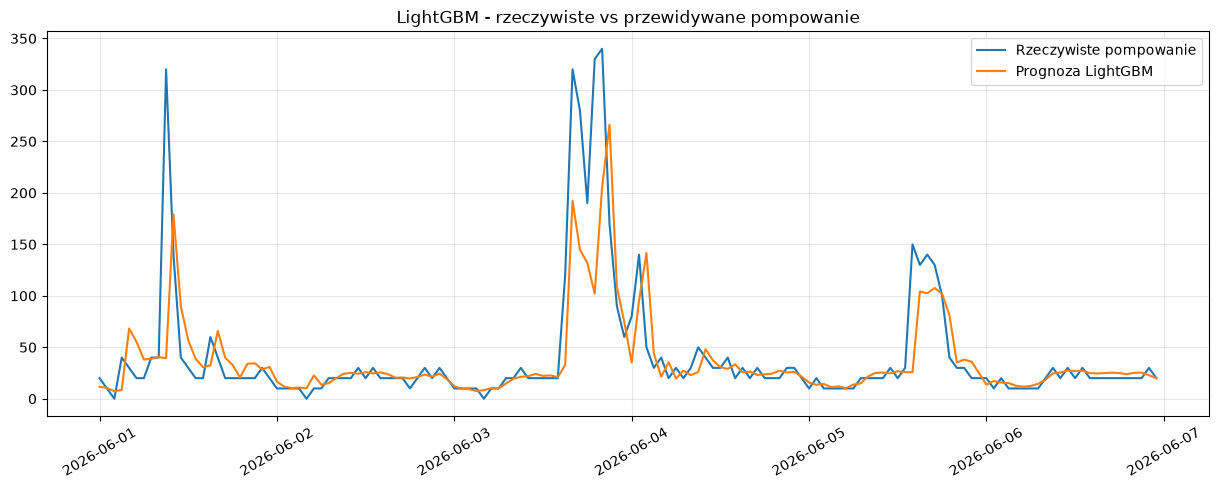

In [215]:
results_val = pd.DataFrame({
    "rzeczywiste": y_val,
    "prognoza": y_pred_val
}, index=y_val.index)

sample = results_val.loc["2026-06-01":"2026-06-06"]

plt.figure(figsize=(15, 5))

plt.plot(
    sample.index,
    sample["rzeczywiste"],
    label="Rzeczywiste pompowanie"
)

plt.plot(
    sample.index,
    sample["prognoza"],
    label="Prognoza LightGBM"
)

plt.title("LightGBM - rzeczywiste vs przewidywane pompowanie")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()


In [216]:
results_val["residual"] = results_val["rzeczywiste"] - results_val["prognoza"] #różnica między rzeczywistym, a przewidywanym pompowaniem
results_val["excess"] = results_val["residual"].clip(lower=0) #potencjalna nadwyżka

print(results_val[["residual", "excess"]].describe())

          residual       excess
count  2627.000000  2627.000000
mean      0.118167     4.031116
std      20.454975    16.795149
min    -172.599249     0.000000
25%      -4.003939     0.000000
50%      -1.324832     0.000000
75%       3.265043     3.265043
max     307.220233   307.220233


In [217]:
results_val["opad_6h"] = df_lgbm.loc[results_val.index, "opad_6h"]
results_val["opad_24h"] = df_lgbm.loc[results_val.index, "opad_24h"]
results_val["opad_48h"] = df_lgbm.loc[results_val.index, "opad_48h"]
results_val["opad_72h"] = df_lgbm.loc[results_val.index, "opad_72h"]

results_val.head()

,rzeczywiste,prognoza,residual,excess,opad_6h,opad_24h,opad_48h,opad_72h
Data_czas,,,,,,,,
2026-03-08 00:00:00,10.0,11.251517,-1.251517,0.000000,0.0,0.0,0.0,0.0
2026-03-08 01:00:00,20.0,13.705790,6.294210,6.294210,0.0,0.0,0.0,0.0
2026-03-08 02:00:00,10.0,11.455747,-1.455747,0.000000,0.0,0.0,0.0,0.0
2026-03-08 03:00:00,0.0,7.843727,-7.843727,0.000000,0.0,0.0,0.0,0.0
2026-03-08 04:00:00,10.0,9.477915,0.522085,0.522085,0.0,0.0,0.0,0.0


In [218]:
def rolling_threshold(sm, window="30D", method="mad", k=4.0, min_periods = 24*7, step ="1h"):
    sm_step = sm.resample(step).mean()
    r = sm_step.rolling(window, min_periods, closed="left")

    if method == "mad":
        med = r.median()
        mad = (sm_step - med).abs().rolling(window, min_periods, closed="left").median()
        thr = med + k * 1.4826 * mad
    elif method == "tukey":
        q1, q3 = r.quantile(0.25), r.quantile(0.75)
        thr = q3 + 1.5 * (q3-q1)
    else: 
        raise ValueError

    return thr.reindex(sm.index, method="ffill")

In [219]:
results_val["threshold"] = rolling_threshold(results_val["residual"])

results_val["anomaly_lgbm"] = (
    (results_val["residual"] > results_val["threshold"]) &
    (results_val["residual"] > 0)
)

print("Liczba anomalnych godzin:", results_val["anomaly_lgbm"].sum())
print("Godziny z wyznaczonym progiem:", results_val["threshold"].notna().sum())

Liczba anomalnych godzin: 83
Godziny z wyznaczonym progiem: 2291


In [220]:
hot = results_val.loc[results_val["anomaly_lgbm"], "residual"]

new_alarm = hot.index.to_series().diff() > pd.Timedelta("180min")
new_alarm.iloc[0] = True

alerts_df = pd.DataFrame({
    "datetime": hot.index[new_alarm.values],
    "residual": hot[new_alarm.values].values
})

print("Liczba alarmów:", len(alerts_df))

Liczba alarmów: 40


In [221]:
alerts_df = alerts_df.set_index("datetime")

alerts_df = alerts_df.join(
    results_val[["opad_6h", "opad_24h", "opad_48h", "opad_72h"]]
)

display(alerts_df.head(10))

,residual,opad_6h,opad_24h,opad_48h,opad_72h
datetime,,,,,
2026-03-25 23:00:00,20.016259,0.1,0.1,0.1,0.1
2026-03-28 01:00:00,90.477067,1.6,2.6,17.6,18.3
2026-03-28 07:00:00,102.772508,0.8,3.1,11.9,19.1
2026-03-28 23:00:00,20.562961,0.4,2.0,4.2,19.5
2026-03-31 00:00:00,33.477936,0.1,0.1,NaN,NaN
2026-03-31 07:00:00,55.628471,4.4,4.9,4.9,NaN
2026-04-14 04:00:00,34.407233,0.0,0.0,0.0,0.0
2026-04-14 23:00:00,24.999768,0.1,0.1,0.1,0.1
2026-04-15 07:00:00,33.953054,0.3,1.1,1.1,1.1


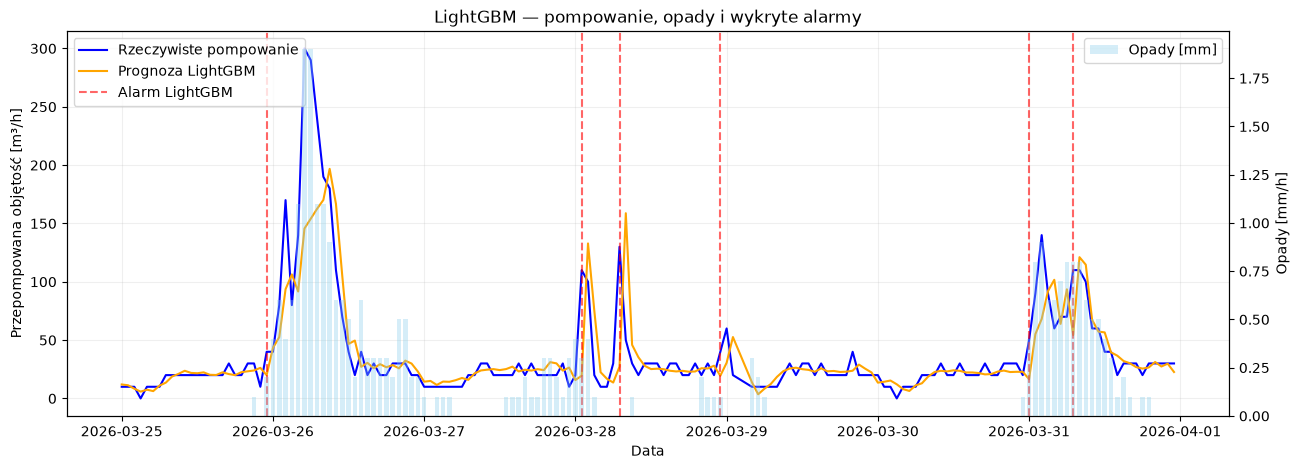

In [224]:
start = "2026-03-25"
end = "2026-04-01"

df_plot = results_val.loc[start:end].copy()
df_plot = df_plot[df_plot.index < pd.Timestamp(end)]

alarms_plot = alerts_df.loc[start:end]
alarms_plot = alarms_plot[alarms_plot.index < pd.Timestamp(end)]

fig, ax1 = plt.subplots(figsize=(15, 5))

# Rzeczywiste i przewidywane pompowanie
ax1.plot(
    df_plot.index, df_plot["rzeczywiste"],
    label="Rzeczywiste pompowanie",
    color="blue"
)

ax1.plot(
    df_plot.index, df_plot["prognoza"],
    label="Prognoza LightGBM",
    color="orange"
)

# Wykryte alarmy
for i, date in enumerate(alarms_plot.index):
    ax1.axvline(
        date,
        color="red",
        linestyle="--",
        alpha=0.6,
        label="Alarm LightGBM" if i == 0 else None
    )

# Opady godzinowe na drugiej osi
ax2 = ax1.twinx()

ax2.bar(
    df_plot.index,
    df_lgbm.loc[df_plot.index, "suma_opadu_mm"],
    width=0.03,
    color="skyblue",
    alpha=0.35,
    label="Opady [mm]"
)

ax1.set_ylabel("Przepompowana objętość [m³/h]")
ax2.set_ylabel("Opady [mm/h]")
ax1.set_xlabel("Data")
ax1.set_title("LightGBM — pompowanie, opady i wykryte alarmy")

ax1.legend(loc="upper left")
ax2.legend(loc="upper right")
ax1.grid(alpha=0.2)

plt.show()